# Phase 3 — Fixed LiteCrack evaluation

No retraining or threshold tuning. Replays recorded validation scores before
evaluating 237 source holdout and 95 target-query images at threshold 0.5.
Adds deterministic prediction previews for visual inspection. Keep the saved
Phase 3 checkpoints unchanged. Use the same Kaggle session, or attach the
verified phase3_results.zip as Kaggle input if the session has reset.


In [2]:
expected_files={'artifacts/dataset_restore.json': '214198c56e4b3668f1de4e535a35130828097052bf3914e6eef5c14260aa1d73', 'artifacts/phase1/environment.json': '0c297add6404b6a1035b71c2cec0737c3af9b6b2ebd8a82f8e8cc81844ed688b', 'artifacts/phase3/litecrack/checkpoints/best.json': '2dfdcca8668156f7647238ae34e971b7552b65a6be74b9aceb66f163b225512b', 'artifacts/phase3/litecrack/checkpoints/latest.json': '478e85657f08c3b032713e8492081797a21917688c454c7ced3b665e8e9f3767', 'artifacts/phase3/litecrack/checkpoints/step-000002970-92069633.pt': '9ac52e68c86938f826ddf9bf5176ce8abba830c4ecb3cdd01dd35823777c1fa2', 'artifacts/phase3/litecrack/checkpoints/step-000003000-79b0a41a.pt': '1d88d2f70b9f44470fe45dcf2834ba21f6a5e802ad8dc1df6e9d44425512e198', 'artifacts/phase3/litecrack/config.json': 'c607602bba78dde827a477e5b1613b38d0a7808645e8ae66311e7f7f977b7e56', 'artifacts/phase3/litecrack/environment.json': '50f5834685be708a6c6d7b679c6a56b7a546e6eb079a0db8edcc842c4129bf9c', 'artifacts/phase3/litecrack/evaluation.json': 'd21ee6e0825963caa13b47810bcd2e336e77f88681f3776cc4c5177f45b47058', 'artifacts/phase3/litecrack/history.json': '5abccf307b6d5e13fd55d7aa62503859e0927e4a7b773ca884e8eff4161d52ef', 'artifacts/phase3/litecrack/manifest.json': '9c97554166af5494c746d46885425f748ea46c4035863c22c90215b3506358ae', 'artifacts/phase3/litecrack/profile_cpu.json': 'a89a9dbc72a39d8d05fced673cf0c89d254e69c6cf13e47e17041b46b00ac337', 'artifacts/phase3/litecrack/profile_cuda.json': '8db72d925f37716db44d672264397eee6a7501213f2a947723fdd5dea4a732dc', 'artifacts/phase3/litecrack/source_validation_per_image.json': 'd1b514ed32da6892e919be519d5bc61b402d1121fbcaa199aa468b5eb2d4c5fd', 'artifacts/phase3/litecrack/status.json': 'ba249456a441ed9c618bc77ca6a30eb70a9309062a95a70e2e49345bbdff84e3', 'artifacts/phase3/profile_cpu.log': '119ee0f32c7719a7bcd507432e826bb9fa3a76ea010764e8a8effc34fc29a663', 'artifacts/phase3/profile_cuda.log': 'bf21906b30a576839d2e6cd1c48fd36b33f93038756ba3aa4db53c7b9b54e8ec', 'artifacts/phase3/requirements.kaggle.lock.txt': '75abf5a5b84e04e2e3ba62cbad028024968b3336d10544c8479fe9e5f0918313', 'artifacts/phase3/tests.txt': '35af24e44967e6edfec2374d3ce17a9c38dee713b50aacdeb2608a1d89ee03ca', 'artifacts/phase3/tests.xml': '476d93d2bfea2af96fdf327ab2c8e713363499f7a79419c05397980d7ae0233d', 'artifacts/phase3/training.log': '96e39705f42bd47b60aee4b3b47dbebdcedb61fbffdfe8a524cb751051c0cdb7', 'configs/baseline_r2au.json': '76f058a412db7f81d4b925223f3e91b53ae5d1b893dda58f65974bb4151d0577', 'configs/baseline_unet.json': '205b44ada0cf895862f3bb31a33041b786b1eed24c880c38b9c083f475c9659c', 'configs/data_sources.json': 'e33ad521df49827fc30af7308541af4fb2a2b69ccd34ac919c19d2ddc5861c1f', 'configs/litecrack.json': 'fc99fafbcd4e4e5c5cf50d57d027271e71b0b0f4830af7196ab896a20c925fa4', 'configs/phase1.json': '51484e20e224486e7db55fab2ed8a0ded307cf2962fd53467c4b5311c1caf1e4', 'configs/stabilized_r2au.json': '197ffd9b58eec40d9e3e5de225e6890d869424e5900bbe2471dd15535a020be3', 'configs/stabilized_unet.json': 'fcd8006ecbd6c4ecbfcbb33c850c7736868a443dd95aa5551a3edc8bf2d03e08', 'data/manifests/baseline_registry_v1.json': '365e9d8c74d39e6bebf6f82c980a0148f5708bbfc17886adc688edca9e8c1f21', 'data/manifests/pilot_v1.json': '9c97554166af5494c746d46885425f748ea46c4035863c22c90215b3506358ae', 'data/manifests/pilot_v1.json.sha256': 'e04269dae5566234d83b5c20a6c631baaba57092fbb4e62dcf0f910c3bb05364', 'requirements.txt': '6f109fbff5a330a6e0f57b1a687e466ab0b330fa3921774e5e0310e65e3ee512', 'scripts/audit_kaggle_data.py': '463dce488a03d7a432df6c16bba74ae619fbf41b08b413e27aa90e6e2fa222da', 'scripts/build_data_audit_notebook.py': '68c90fa0accc72b22022ed11994d038f1812a7cb19f295d84ccadf50d1029ba0', 'scripts/build_final_evaluation_notebook.py': 'caf2d85b5d6d1b57eacd4f43bcd7116382e84a169c99acfa3013d8975b4098f2', 'scripts/build_kaggle_notebook.py': 'd121b7956103c42e9f2b340387286f623172e8e01792ddcaa358541a468af79d', 'scripts/build_phase2_notebook.py': 'dc05c84ebad18b9f3828f78563bb75bf2d954eea3874d428b68eb36e9390d8e0', 'scripts/environment.py': 'e0386ae0d9a9ef13a5fb27d3464b2afa2faa1181a055fbaf3b9aae48702183c3', 'scripts/evaluate_frozen_baselines.py': '864af8feb41d08786629a4f0f2ef4aea8f7c69e365e60ef8fcc3830890f1f6b8', 'scripts/freeze_pilot.py': 'bf7edba7258f0ab9750ff1197b12cce850f71b0d278de3fa353399b9ad45de85', 'scripts/prepare_data.py': 'fc59ddd85cde50d1e30d7d988ad8c2f898c11deb0223119e66149a67c3e54c25', 'scripts/profile_baseline.py': 'f62e6f9e121255193add4ef575d5c77d2503b02337dcacac4e483cdc445faa41', 'scripts/restore_datasets.py': '0d7fc8fd923c817c1da393abe2b76a4b49625a433f8724a88b62bd97f2791a5b', 'scripts/train_baseline.py': '2e1ec42b0d7f62ae92553d1f65096f252918a3d826a5d33ce2f96e443b6c09ec', 'src/__init__.py': '8ccf2c63120e3ea084ae3827cd5d4189d092f266d9ce6e11a97fb2b5aa175bef', 'src/atomic.py': '8d3e04bad91ed969540d145613c83b719c69f3346bf5ced3bda46dec5be84823', 'src/checkpoints.py': '0a34e05d17f4b4d255abdc48b38b6c429a6427ac8fe351d9a1204d40bd783264', 'src/dataset.py': 'a472d7c679edd5fadb974b8ef168db29ddcf2288a2beca23345a0e3379fafc57', 'src/litecrack.py': '2c944b12a9f95d19284a2478a1457d53c7af6fac02601761c19bea3f9384b6d9', 'src/model_factory.py': '890fdc511753cd6357caeeccbe2a125878d223fb25607223a34b0e7f76198110', 'src/models.py': '011980f40fc4c97b2a42a39048231d10e157e5e38bb70ffd6ef33f27de1214e5', 'src/segmentation.py': '9016f5ba4cb859c9f448e3889b0d8f04cd3a3f5848e5ca59898db96cbdb082b5', 'tests/test_checkpoint_resume.py': 'fc852c67163aaee31d4cb93b64b4c077fc888d52ad5eb99778553c3287f0a56e', 'tests/test_data_audit.py': '222b4de7fb5c2efed6183b95c90d8b0ca173c3e59c1ef19d9a4362cd3ab0d277', 'tests/test_dataset_restore.py': 'f480b83820f37077d605546b692483af8dbf844b3347a494bd7c28fe6f4ac7c4', 'tests/test_foundation.py': 'b511f320a296782b354c4169d4fff15428180dbc436aede61aa52b2c2c778c39', 'tests/test_litecrack.py': '9d2d3021527adbbf8a60a1a5ba9bc43f5b0b60fb3933342db41ec397b8fcb3e3', 'tests/test_pair_discovery.py': '78873635f09924fcd8f0174dda4cf8621576f22499807ab60b665a3f74cff440', 'tests/test_phase2.py': 'c4e23a1ce0a5df9fdcef14342ed574e456f5abc0b72623799ed6935625a2b903'}
import os,sys,json,hashlib,zipfile,subprocess,shutil
from pathlib import Path
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
project=Path('/kaggle/working/road_crack_phase3_v1')
if not (project/'artifacts/phase3/litecrack/checkpoints/best.json').exists():
    candidates=list(Path('/kaggle/input').rglob('phase3_results.zip'))
    local=Path('/kaggle/working/phase3_results.zip')
    if local.exists(): candidates.insert(0,local)
    project.mkdir(exist_ok=True)
    if candidates:
        archive=candidates[0]
        assert hashlib.sha256(archive.read_bytes()).hexdigest()=='d1d9c4fa7c42efb64e2f30f775fbbf8f5973f22676f591ba1537523d63119470', 'Unexpected backup checksum'
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                path=(project/name).resolve(); assert path.is_relative_to(project.resolve())
                if path.exists(): assert path.read_bytes()==z.read(name), 'Existing file differs: preserve and inspect'
            z.extractall(project)
    else:
        extracted=[p.parents[4] for p in Path('/kaggle/input').rglob('best.json')
                   if p.as_posix().endswith('/artifacts/phase3/litecrack/checkpoints/best.json')]
        valid=[]
        for candidate in extracted:
            if all((candidate/name).is_file() and hashlib.sha256((candidate/name).read_bytes()).hexdigest()==digest
                   for name,digest in expected_files.items()): valid.append(candidate)
        assert valid, 'Attach phase3_results.zip or its complete extracted contents as Kaggle input'
        for name,digest in expected_files.items():
            path=(project/name).resolve(); assert path.is_relative_to(project.resolve())
            if path.exists(): assert hashlib.sha256(path.read_bytes()).hexdigest()==digest, 'Existing file differs; preserve and inspect'
        for name in expected_files:
            path=project/name; path.parent.mkdir(parents=True,exist_ok=True)
            if not path.exists(): shutil.copyfile(valid[0]/name,path)
        print('Restored extracted Kaggle input; all backup file hashes verified.')
os.chdir(project)
script=project/'scripts/evaluate_litecrack.py'
source='"""Evaluate the immutable Phase 3 region-only checkpoint, without any tuning."""\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport random\nimport sys\n\nsys.path.insert(0,str(Path(__file__).resolve().parents[1]))\nimport numpy as np\nimport torch\nfrom PIL import Image,ImageDraw\nfrom src.atomic import write_json\nfrom src.dataset import CrackDataset,verify_files\nfrom src.model_factory import build_model\nfrom scripts.train_baseline import evaluate\n\n\n@torch.no_grad()\ndef preview(model,dataset,device,output,split):\n    indices=random.Random(42).sample(range(len(dataset)),min(6,len(dataset)))\n    sheet=Image.new(\'RGB\',(1024,280*len(indices)),\'white\')\n    draw=ImageDraw.Draw(sheet)\n    for j,index in enumerate(indices):\n        image,truth=dataset[index]\n        probability=model(image[None].to(device)).sigmoid()[0,0].cpu().numpy()\n        prediction=(probability>=.5).astype(np.uint8)*255\n        original=Image.fromarray((image.numpy().transpose(1,2,0)*255).astype(np.uint8))\n        target=Image.fromarray((truth[0].numpy()*255).astype(np.uint8))\n        mask=Image.fromarray(prediction)\n        overlay=Image.composite(Image.blend(original,Image.new(\'RGB\',original.size,\'red\'),.55),original,mask)\n        for column,view in enumerate((original,target.convert(\'RGB\'),mask.convert(\'RGB\'),overlay)):\n            sheet.paste(view.resize((256,256)),(column*256,j*280+24))\n        draw.text((2,j*280+4),dataset.rows[index][\'image_id\']+\' | image / truth / prediction / overlay\',fill=\'black\')\n        mask.save(output/f\'{split}_preview_mask_{j}.png\')\n    sheet.save(output/f\'{split}_predictions.jpg\',quality=92)\n    return [dataset.rows[index][\'image_id\'] for index in indices]\n\n\ndef run_evaluation(project,data_root,output):\n    project,output=Path(project),Path(output)\n    if output.exists(): raise ValueError(\'Output exists; use a new directory and preserve prior results\')\n    manifest_path=project/\'data/manifests/pilot_v1.json\'\n    raw_manifest=manifest_path.read_bytes()\n    manifest_hash=hashlib.sha256(raw_manifest).hexdigest()\n    if manifest_hash!=manifest_path.with_suffix(\'.json.sha256\').read_text().split()[0]:\n        raise ValueError(\'Manifest hash mismatch\')\n    manifest=json.loads(raw_manifest)\n    verify_files(manifest[\'records\'],data_root)\n    run=project/\'artifacts/phase3/litecrack\'\n    pointer=json.loads((run/\'checkpoints/best.json\').read_text())\n    path=(run/\'checkpoints\'/pointer[\'file\']).resolve()\n    if path.parent!=(run/\'checkpoints\').resolve(): raise ValueError(\'Unsafe checkpoint path\')\n    if hashlib.sha256(path.read_bytes()).hexdigest()!=pointer[\'sha256\']:\n        raise ValueError(\'Checkpoint hash mismatch\')\n    # This is the trusted snapshot from the already-verified Phase 3 archive.\n    state=torch.load(path,map_location=\'cpu\',weights_only=False)\n    if state[\'manifest_hash\']!=manifest_hash: raise ValueError(\'Checkpoint used different splits\')\n    config=state[\'config\']\n    if config[\'architecture\']!=\'litecrack\': raise ValueError(\'Expected region-only LiteCrack\')\n    if not torch.cuda.is_available(): raise RuntimeError(\'Enable the Kaggle GPU runtime\')\n    torch.use_deterministic_algorithms(True); torch.backends.cudnn.benchmark=False\n    device=torch.device(\'cuda\')\n    model=build_model(config).to(device)\n    model.load_state_dict(state[\'model\'])\n    validation=CrackDataset(manifest,data_root,\'source_validation\',config[\'image_size\'])\n    replay,_=evaluate(model,validation,device,config[\'batch_size\'])\n    recorded=json.loads((run/\'evaluation.json\').read_text())[\'results\'][\'source_validation\']\n    for metric in (\'dice\',\'iou\',\'precision\',\'recall\'):\n        if abs(replay[metric]-recorded[metric])>1e-5:\n            raise ValueError(\'Validation replay mismatch; stopping before holdout/query evaluation\')\n    output.mkdir(parents=True)\n    results,preview_ids={},{}\n    for split in (\'source_holdout\',\'target_query\'):\n        dataset=CrackDataset(manifest,data_root,split,config[\'image_size\'])\n        metrics,rows=evaluate(model,dataset,device,config[\'batch_size\'])\n        results[split]=metrics\n        write_json(output/f\'litecrack_{split}_per_image.json\',rows)\n        preview_ids[split]=preview(model,dataset,device,output,split)\n    report={\'manifest_sha256\':manifest_hash,\'architecture\':\'litecrack\',\n            \'checkpoint_sha256\':pointer[\'sha256\'],\'best_epoch\':pointer[\'epoch\'],\n            \'threshold\':.5,\'validation_replay\':replay,\'results\':results,\n            \'preview_ids\':preview_ids,\'preview_selection\':\'seed 42, six samples per split; not cherry-picked\',\n            \'scope\':\'Fixed region-only model; no training, adaptation or threshold tuning; exploratory target query previously used\'}\n    write_json(output/\'evaluation.json\',report)\n    print(json.dumps(report,indent=2),flush=True)\n    return report\n\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--project\',type=Path,required=True)\n    p.add_argument(\'--data-root\',type=Path,required=True)\n    p.add_argument(\'--output\',type=Path,required=True)\n    a=p.parse_args(); run_evaluation(a.project,a.data_root,a.output)\n'
if script.exists(): assert script.read_text()==source, 'Existing evaluation code differs; preserve and inspect'
else: script.write_text(source)

restore_report=project/'artifacts/final_eval_dataset_restore.json'
subprocess.run([sys.executable,'scripts/restore_datasets.py','--manifest','data/manifests/pilot_v1.json',
    '--sources','configs/data_sources.json','--destination','/kaggle/working/road_crack_phase1/data/raw',
    '--report',str(restore_report)],check=True)
data_root=Path(json.loads(restore_report.read_text())['data_root'])


Restored extracted Kaggle input; all backup file hashes verified.
Previous data unavailable/incomplete. Restoring pinned repositories to: /kaggle/working/road_crack_phase1/data/raw


HEAD is now at 8202a60 Update README.md
HEAD is now at bd8fbd7 Add files via upload


Restoration complete: verified 657 pairs against the unchanged frozen manifest


In [3]:
from datetime import datetime,timezone
output=project/'artifacts'/('phase3_final_evaluation_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
result=subprocess.run([sys.executable,'scripts/evaluate_litecrack.py','--project',str(project),
    '--data-root',str(data_root),'--output',str(output)],text=True,capture_output=True)
execution_log=output.with_suffix('.log')
execution_log.write_text(result.stdout+result.stderr)
print(result.stdout,result.stderr)
assert result.returncode==0, 'Evaluation failed; retain execution log for diagnosis'


{
  "manifest_sha256": "9c97554166af5494c746d46885425f748ea46c4035863c22c90215b3506358ae",
  "architecture": "litecrack",
  "checkpoint_sha256": "9ac52e68c86938f826ddf9bf5176ce8abba830c4ecb3cdd01dd35823777c1fa2",
  "best_epoch": 99,
  "threshold": 0.5,
  "validation_replay": {
    "loss": 0.40793500741322836,
    "dice": 0.7372418018368383,
    "iou": 0.6223634694780533,
    "precision": 0.7131622011773289,
    "recall": 0.7819713837156693,
    "predicted_foreground_fraction": 0.02988154093424479,
    "truth_foreground_fraction": 0.028463999430338543,
    "n": 60
  },
  "results": {
    "source_holdout": {
      "loss": 0.3660304286057436,
      "dice": 0.7636097642565578,
      "iou": 0.6370104540626711,
      "precision": 0.8446032636905019,
      "recall": 0.730624828676257,
      "predicted_foreground_fraction": 0.03554853613052187,
      "truth_foreground_fraction": 0.04327650113573557,
      "n": 237
    },
    "target_query": {
      "loss": 0.7106475108548215,
      "dice": 0.3

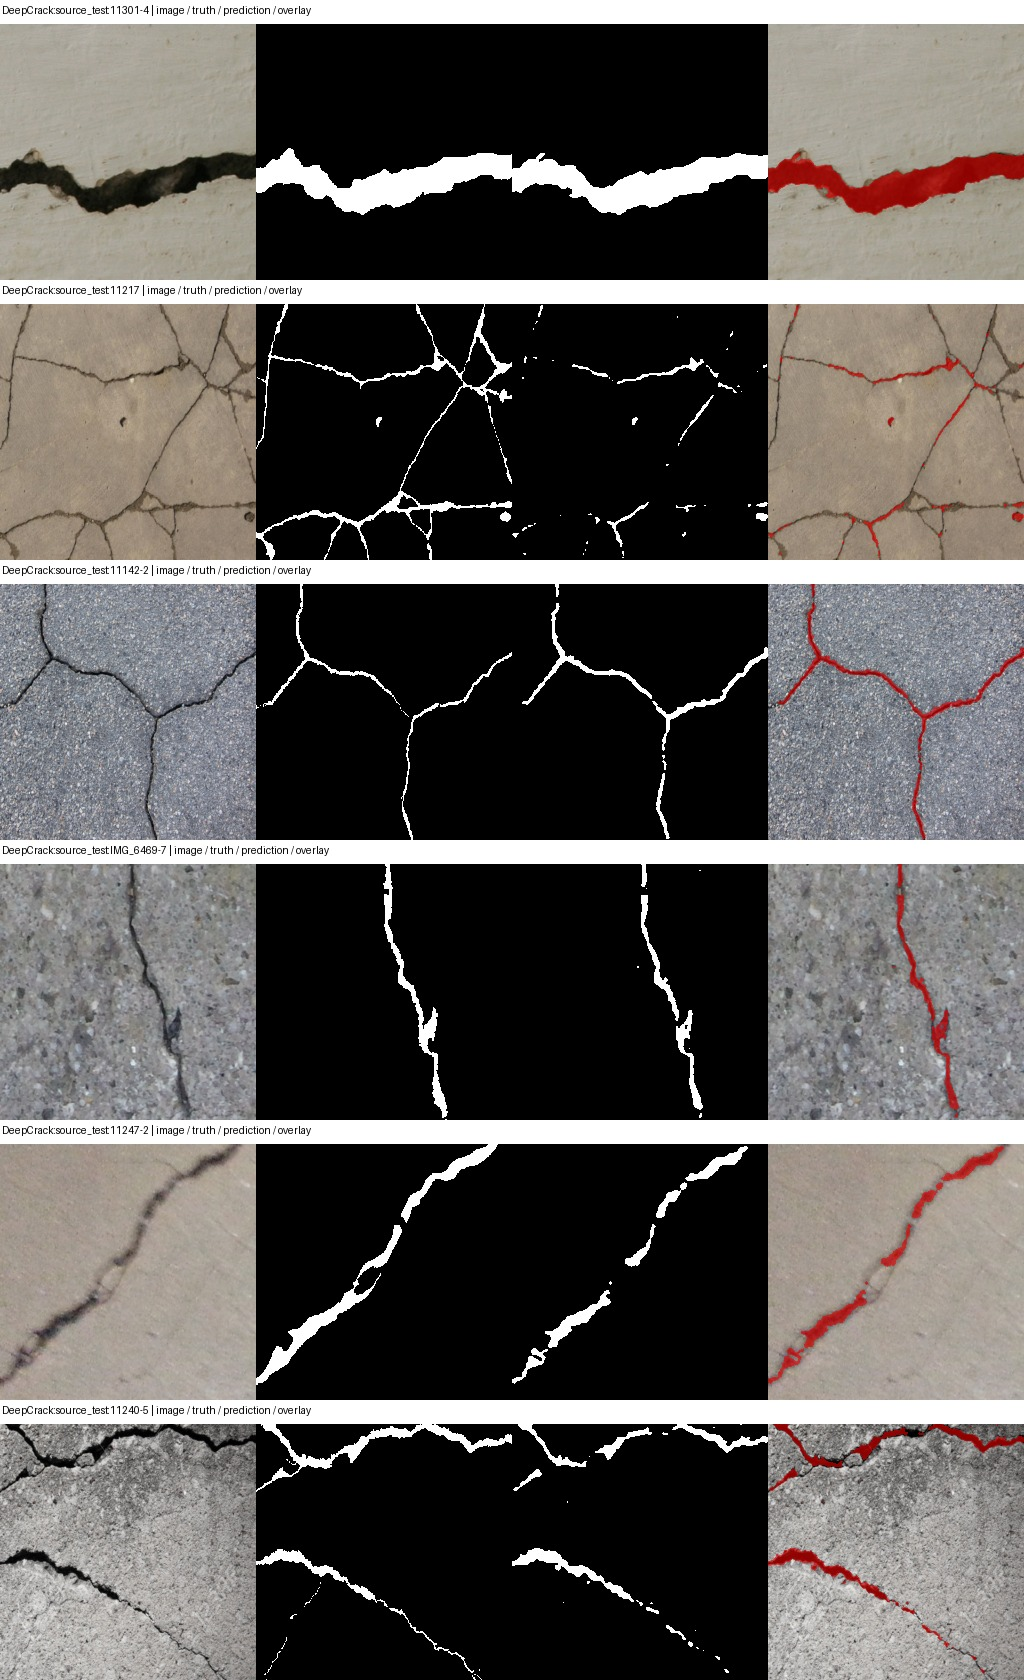

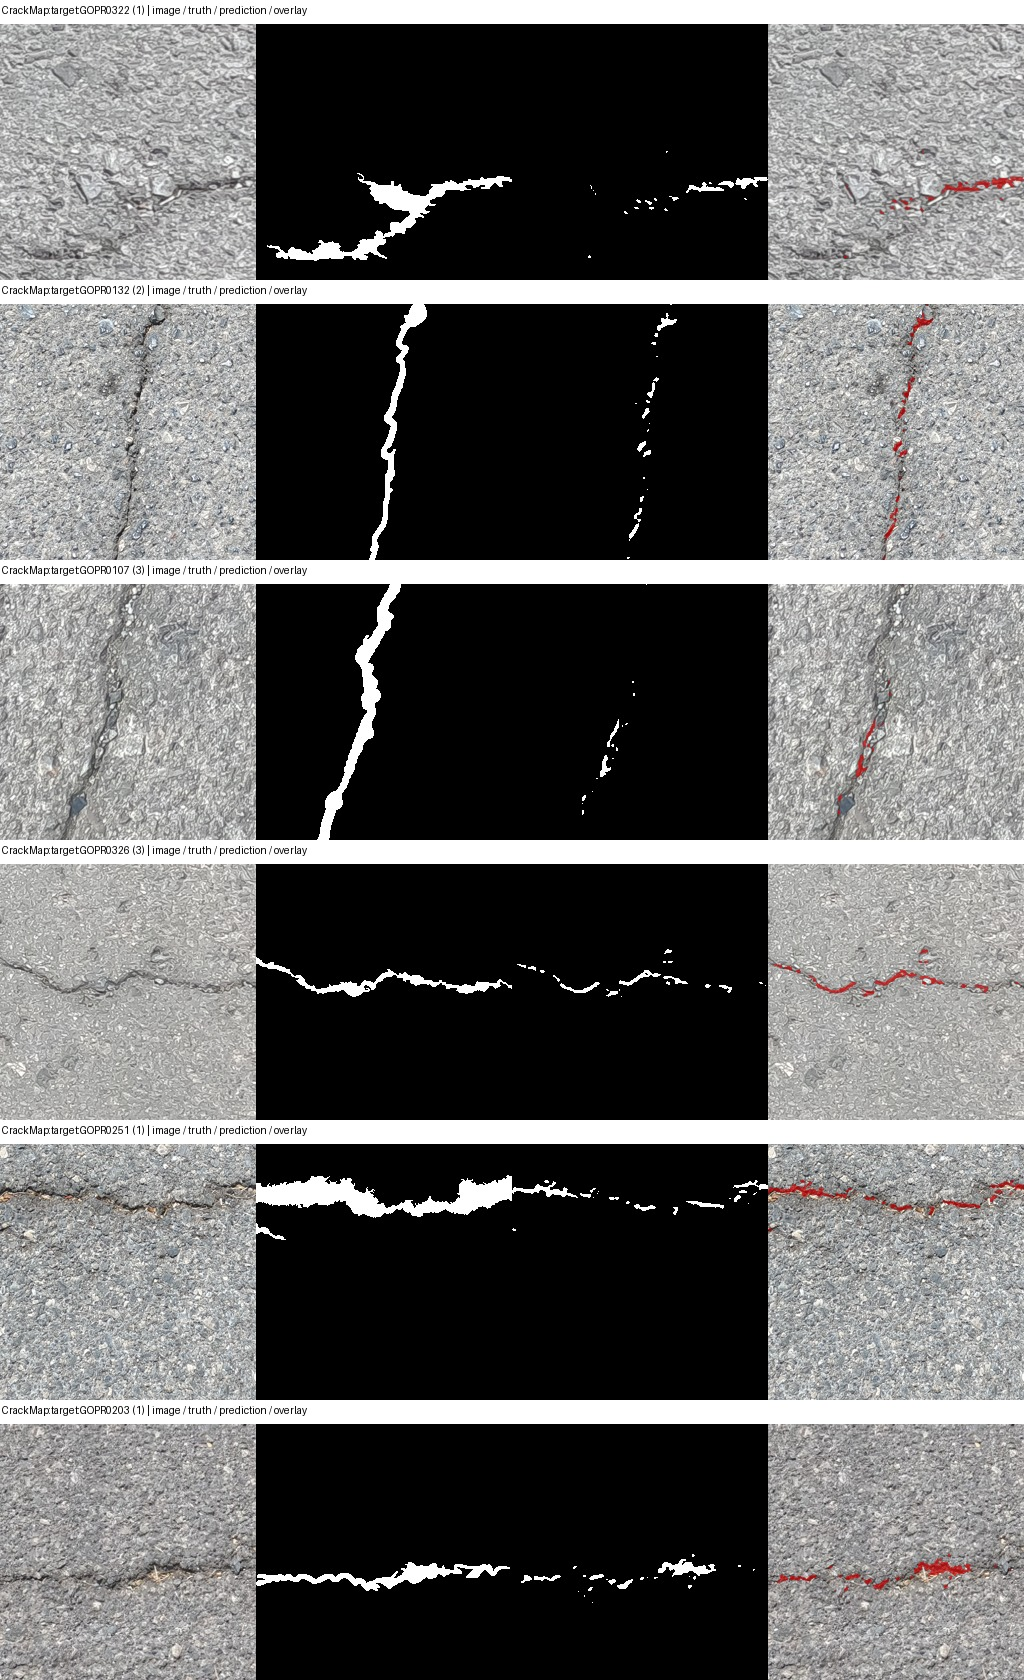

In [4]:
from IPython.display import display,Image
for split in ['source_holdout','target_query']:
    display(Image(filename=str(output/(split+'_predictions.jpg'))))


In [5]:
backup=Path('/kaggle/working/phase3_final_evaluation.zip')
with zipfile.ZipFile(backup,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(output.rglob('*')):
        if p.is_file(): z.write(p,p.relative_to(output).as_posix())
    z.write(script,'evaluate_litecrack.py')
    z.write(execution_log,'execution.log')
digest=hashlib.sha256(backup.read_bytes()).hexdigest()
backup.with_suffix('.zip.sha256').write_text(digest+'  '+backup.name+'\n')
print('Download from Kaggle Files:',backup)
print('SHA256:',digest)


Download from Kaggle Files: /kaggle/working/phase3_final_evaluation.zip
SHA256: 5906263ae6885ebd412e3862297c31d1306af71aa4c794eb615885d7d6aa57e9
